<a href="https://colab.research.google.com/github/Tanisha-dey18/small---project-2/blob/main/AIML_Lab_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install ucimlrepo

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score, RocCurveDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [ ]:
raisin = fetch_ucirepo(id=850)
X = raisin.data.features.copy()
y = raisin.data.targets.copy()
if isinstance(y, pd.DataFrame):
  y = y.iloc[:, 0]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())
display(y.value_counts())

Feature shape: (900, 7)
Target shape: (900,)


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251


,count
Class,
Kecimen,450
Besni,450


In [ ]:
print("Data types:")
display(X.dtypes.to_frame("dtype"))
print("Missing values:")
display(X.isnull().sum().to_frame("missing"))
print("Duplicate feature rows:", X.duplicated().sum())

X = X.apply(pd.to_numeric, errors="coerce")
if X.isnull().any().any():
    X = X.fillna(X.median(numeric_only=True))

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y.astype(str))
print("Class mapping:", dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))

Data types:


,dtype
Area,int64
MajorAxisLength,float64
MinorAxisLength,float64
Eccentricity,float64
ConvexArea,int64
Extent,float64
Perimeter,float64


Missing values:


,missing
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
Extent,0
Perimeter,0


Duplicate feature rows: 0
Class mapping: {'Besni': np.int64(0), 'Kecimen': np.int64(1)}


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=RANDOM_STATE,
    stratify=y_encoded
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training class proportions:")
print(pd.Series(y_train).value_counts(normalize=True).sort_index())
print("Testing class proportions:")
print(pd.Series(y_test).value_counts(normalize=True).sort_index())

Training samples: 720
Testing samples: 180
Training class proportions:
0    0.5
1    0.5
Name: proportion, dtype: float64
Testing class proportions:
0    0.5
1    0.5
Name: proportion, dtype: float64


In [ ]:
display(pd.DataFrame({
    "minimum": X_train.min(),
    "maximum": X_train.max(),
    "range": X_train.max() - X_train.min()
}).sort_values("range", ascending=False))

,minimum,maximum,range
ConvexArea,26139.000000,278217.000000,252078.000000
Area,25387.000000,235047.000000,209660.000000
Perimeter,619.074000,2697.753000,2078.679000
MajorAxisLength,225.629541,997.291941,771.662400
MinorAxisLength,143.710872,492.275279,348.564407
Eccentricity,0.348730,0.962124,0.613395
Extent,0.379856,0.824319,0.444463


In [ ]:
linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])
linear_svm.fit(X_train, y_train)
pred_linear = linear_svm.predict(X_test)
print("Linear SVM trained.")

Linear SVM trained.


In [ ]:
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

rbf_svm.fit(X_train, y_train)
pred_rbf = rbf_svm.predict(X_test)
print("RBF SVM trained.")

RBF SVM trained.


In [ ]:
def metrics(name, y_true, y_pred):
  return {
      "Model": name,
      "Accuracy": accuracy_score(y_true, y_pred),
      "Precision (weighted)": precision_score(
          y_true, y_pred, average="weighted", zero_division=0
      ),
      "Recall (weighted)": recall_score(
          y_true, y_pred, average="weighted", zero_division=0
      ),
      "F1-score (weighted)": f1_score(
          y_true, y_pred, average="weighted", zero_division=0
      ),
  }
results = pd.DataFrame([
    metrics("Linear SVM", y_test, pred_linear),
    metrics("RBF SVM", y_test, pred_rbf),
])
display(results.round(4))

,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Linear SVM,0.9000,0.9050,0.9000,0.8997
1,RBF SVM,0.8778,0.8871,0.8778,0.8770


In [ ]:
def metrics(name, y_true, y_pred):
  return {
      "Model": name,
      "Accuracy": accuracy_score(y_true, y_pred),
      "Precision (weighted)": precision_score(
          y_true, y_pred, average="weighted", zero_division=0
      ),
      "Recall (weighted)": recall_score(
          y_true, y_pred, average="weighted", zero_division=0
      ),
      "F1-score (weighted)": f1_score(
          y_true, y_pred, average="weighted", zero_division=0
      ),
  }
results = pd.DataFrame([
    metrics("Linear SVM", y_test, pred_linear),
    metrics("RBF SVM", y_test, pred_rbf),
])
display(results.round(4))

,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Linear SVM,0.9000,0.9050,0.9000,0.8997
1,RBF SVM,0.8778,0.8871,0.8778,0.8770


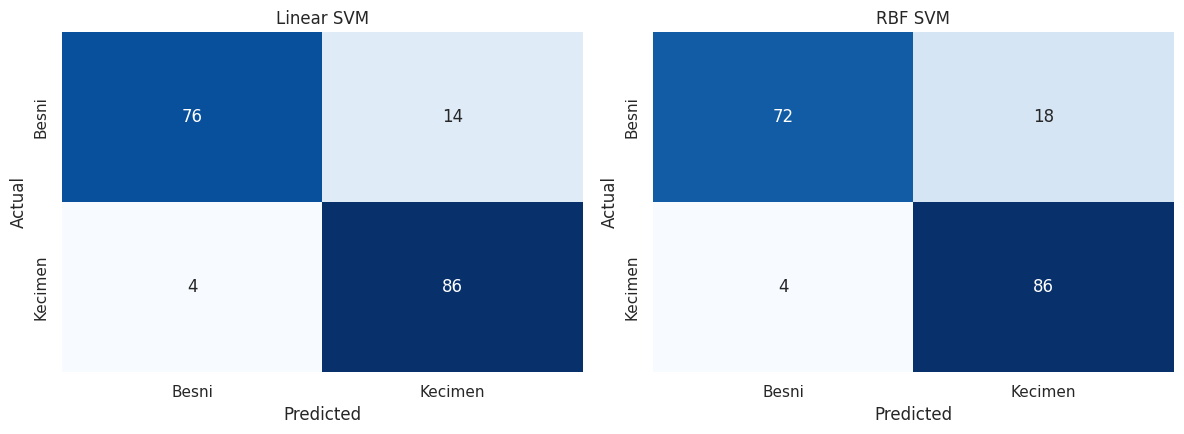

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, title, pred in [
    (axes[0], "Linear SVM", pred_linear),
    (axes[1], "RBF SVM", pred_rbf)
]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=encoder.classes_, yticklabels=encoder.classes_, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
print("LINEAR SVM")
print(classification_report(y_test, pred_linear, target_names=encoder.classes_, zero_division=0))
print("RBF SVM")
print(classification_report(y_test, pred_rbf, target_names=encoder.classes_, zero_division=0))

LINEAR SVM
              precision    recall  f1-score   support

       Besni       0.95      0.84      0.89        90
     Kecimen       0.86      0.96      0.91        90

    accuracy                           0.90       180
   macro avg       0.91      0.90      0.90       180
weighted avg       0.91      0.90      0.90       180

RBF SVM
              precision    recall  f1-score   support

       Besni       0.95      0.80      0.87        90
     Kecimen       0.83      0.96      0.89        90

    accuracy                           0.88       180
   macro avg       0.89      0.88      0.88       180
weighted avg       0.89      0.88      0.88       180



In [ ]:
for name, model in [("Linear SVM", linear_svm), ("RBF SVM", rbf_svm)]:
    svc = model.named_steps["svm"]
    print(name)
    print("Support vectors per class:", svc.n_support_)
    print("Total support vectors:", svc.n_support_.sum())
    print()

Linear SVM
Support vectors per class: [128 130]
Total support vectors: 258

RBF SVM
Support vectors per class: [137 136]
Total support vectors: 273



In [ ]:
c_rows = []
for c in [0.01, 0.1, 1, 10, 100]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=c))
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    c_rows.append({
        "C": c,
        "Accuracy": accuracy_score(y_test, pred),
        "Weighted F1": f1_score(y_test, pred, average="weighted"),
        "Support vectors": model.named_steps["svm"].n_support_.sum()
    })
display(pd.DataFrame(c_rows).round(4))

,C,Accuracy,Weighted F1,Support vectors
0,0.01,0.8778,0.8774,342
1,0.10,0.8722,0.8717,274
2,1.00,0.9000,0.8997,258
3,10.00,0.8944,0.8940,242
4,100.00,0.8889,0.8884,240
